# 03 · Продуктовая аналитика: юнит-экономика, дерево метрик, гипотеза и A/B-тест

Задание: посчитать юнит-экономику по продуктам → найти точки роста → построить дерево метрик →
сформулировать гипотезу → описать A/B-тест длительностью **не больше 2 недель**.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize, proportions_ztest

sys.path.insert(0, str(Path.cwd().parent / "src"))
import cleaning as etl
import viz
from viz import PRIMARY, ACCENT, GOOD, MUTED, save, pct_axis, eur_axis

viz.set_style()
pd.set_option("display.width", 200)

data = etl.load_clean()
deals, calls, spend = data["Deals"], data["Calls"], data["Spend"]
PRODUCTS = ["Digital Marketing", "UX/UI Design", "Web Developer"]

## 1. Юнит-экономика по продуктам

**Юнит** — лид (UA). Период — весь датасет (07.2023–06.2024).

| Метрика | Формула | Смысл |
|---|---|---|
| UA | число лидов | User Acquisition |
| B | студенты | Buyers |
| C1 | B / UA | конверсия в покупателя |
| T | число платежей (рассрочка: 1 платёж/мес. обучения; разовая оплата: 1) | Transactions |
| Revenue | фактически полученная выручка | |
| AOV | Revenue / T | средний платёж |
| APC | T / B | среднее число платежей на студента |
| AC | рекламный бюджет | Acquisition Cost |
| CPA | AC / UA | стоимость лида |
| CAC | AC / B | стоимость студента |
| ARPU | Revenue / UA = C1 · AOV · APC | доход на лида |
| CLTV | AOV · APC | доход на студента |
| CM | Revenue − AC | маржинальная прибыль (до затрат на обучение) |
| ROMI | CM / AC | окупаемость маркетинга |

**Допущения (важно для защиты):**
1. У 82% лидов продукт не указан (не дошли до консультации). Поэтому лиды и рекламный бюджет распределяем
   по продуктам **пропорционально доле продукта среди лидов, у которых он указан**. Альтернатива — считать
   UA только по лидам с продуктом — завысила бы C1 в 5 раз и занизила CPA.
2. Себестоимости обучения (зарплаты преподавателей, платформа) в данных нет → CM считается как
   маржинальная прибыль *после маркетинга*. Это верхняя граница реальной маржи.
3. Выручка — полученная **к дате выгрузки**: многие студенты продолжают учиться и будут платить дальше,
   поэтому для свежих когорт Revenue и APC занижены.

In [2]:
known = deals[deals["product"].isin(PRODUCTS)]
share = known["product"].value_counts(normalize=True).reindex(PRODUCTS)
UA_total, AC_total = len(deals), spend["spend"].sum()

stud = deals[deals["is_student"] & deals["product"].isin(PRODUCTS)]
ue = pd.DataFrame(index=PRODUCTS)
ue["UA"] = (share * UA_total).round()
ue["B"] = stud.groupby("product", observed=True).size().reindex(PRODUCTS)
ue["T"] = stud.groupby("product", observed=True)["payments_count"].sum().reindex(PRODUCTS)
ue["Revenue"] = stud.groupby("product", observed=True)["revenue"].sum().reindex(PRODUCTS)
ue["AC"] = share * AC_total


def add_ratios(t: pd.DataFrame) -> pd.DataFrame:
    t = t.copy()
    t["C1"] = t["B"] / t["UA"]
    t["AOV"] = t["Revenue"] / t["T"]
    t["APC"] = t["T"] / t["B"]
    t["CPA"] = t["AC"] / t["UA"]
    t["CAC"] = t["AC"] / t["B"]
    t["ARPU"] = t["Revenue"] / t["UA"]
    t["CLTV"] = t["AOV"] * t["APC"]
    t["CM"] = t["Revenue"] - t["AC"]
    t["CM_per_UA"] = t["CM"] / t["UA"]
    t["ROMI"] = t["CM"] / t["AC"]
    return t


ue.loc["Total (3 products)"] = ue.sum()
ue = add_ratios(ue)
fmt = {"UA": "{:,.0f}", "B": "{:,.0f}", "T": "{:,.0f}", "Revenue": "€{:,.0f}", "AC": "€{:,.0f}",
       "C1": "{:.2%}", "AOV": "€{:,.0f}", "APC": "{:.2f}", "CPA": "€{:.2f}", "CAC": "€{:,.0f}",
       "ARPU": "€{:.0f}", "CLTV": "€{:,.0f}", "CM": "€{:,.0f}", "CM_per_UA": "€{:.0f}", "ROMI": "{:.0%}"}
ue.style.format(fmt)

,UA,B,T,Revenue,AC,C1,AOV,APC,CPA,CAC,ARPU,CLTV,CM,CM_per_UA,ROMI
Digital Marketing,"10,957",473,"2,768","€2,270,920","€82,655",4.32%,€820,5.85,€7.54,€175,€207,"€4,801","€2,188,265",€200,2647%
UX/UI Design,"5,683",227,"1,113","€940,845","€42,872",3.99%,€845,4.90,€7.54,€189,€166,"€4,145","€897,973",€158,2095%
Web Developer,"3,181",137,474,"€366,580","€23,997",4.31%,€773,3.46,€7.54,€175,€115,"€2,676","€342,583",€108,1428%
Total (3 products),"19,821",837,"4,355","€3,578,345","€149,523",4.22%,€822,5.20,€7.54,€179,€181,"€4,275","€3,428,822",€173,2293%


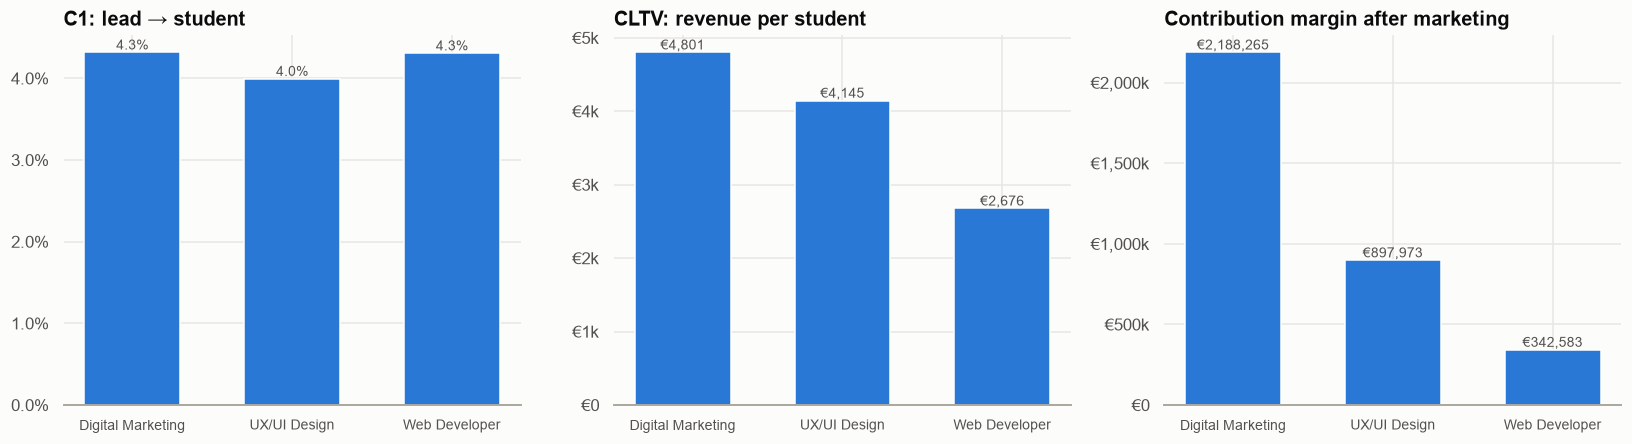

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
p = ue.loc[PRODUCTS]
for ax, col, title, f in [(axes[0], "C1", "C1: lead → student", "pct"),
                          (axes[1], "CLTV", "CLTV: revenue per student", "eur"),
                          (axes[2], "CM", "Contribution margin after marketing", "eur")]:
    ax.bar(p.index, p[col], color=PRIMARY, width=0.6)
    ax.set_title(title); ax.tick_params(axis="x", labelsize=9)
    pct_axis(ax, decimals=1) if f == "pct" else eur_axis(ax)
    for i, v in enumerate(p[col]):
        ax.text(i, v, f"{v:.1%}" if f == "pct" else f"€{v:,.0f}", ha="center", va="bottom", fontsize=9, color=viz.TEXT_2)
plt.tight_layout(); save(fig, "03_unit_economics"); plt.show()

**Чтение юнит-экономики:**
- Все три продукта прибыльны после маркетинга: CAC (≈ €180) в 15–25 раз меньше CLTV. Маркетинг сейчас
  не ограничивает бизнес — ограничивает **конверсия**: из 100 лидов покупают ~4.
- **Digital Marketing** — главный источник прибыли: самый высокий CLTV и наибольшее число студентов.
- **Web Developer** — CLTV вдвое ниже (6-месячный курс дешевле), при той же стоимости лида.
- APC ≈ 5 платежей: студенты в среднем на середине курса — выручка будет расти по мере продолжения обучения.

## 2. Точки роста: анализ чувствительности
Увеличиваем каждую метрику на 10% и смотрим, как меняется CM. При росте UA рекламный бюджет растёт
пропорционально (CPA постоянен); рост C1, AOV, APC бюджета не требует.

,"ΔCM, €","ΔCM, %"
UA +10%,"€342,882",10.0%
C1 +10%,"€357,835",10.4%
AOV +10%,"€357,835",10.4%
APC +10%,"€357,834",10.4%
CPA −10%,"€14,952",0.4%


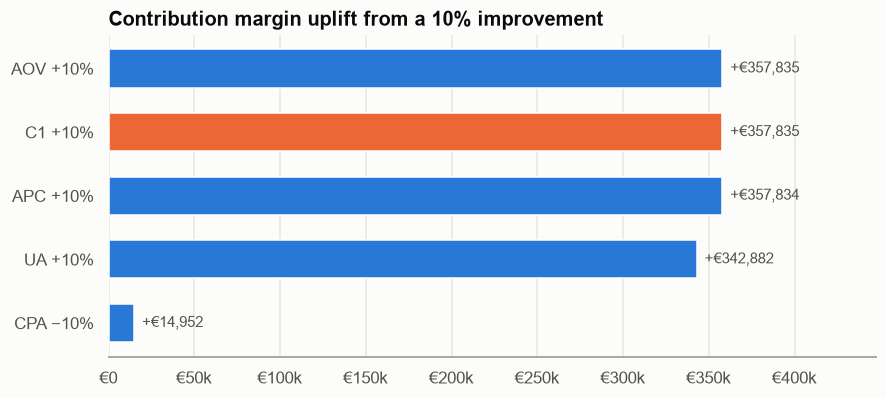

In [4]:
base = ue.loc["Total (3 products)"]


def cm(UA, C1, AOV, APC, CPA):
    return UA * C1 * AOV * APC - UA * CPA


m0 = dict(UA=base["UA"], C1=base["C1"], AOV=base["AOV"], APC=base["APC"], CPA=base["CPA"])
cm0 = cm(**m0)
sens = {}
for k in ["UA", "C1", "AOV", "APC"]:
    m = m0.copy(); m[k] *= 1.10
    sens[k] = cm(**m) - cm0
m = m0.copy(); m["CPA"] *= 0.90
sens["CPA −10%"] = cm(**m) - cm0
sens = pd.Series(sens).rename({"UA": "UA +10%", "C1": "C1 +10%", "AOV": "AOV +10%", "APC": "APC +10%"})
sens_df = pd.DataFrame({"ΔCM, €": sens, "ΔCM, %": sens / cm0})
display(sens_df.style.format({"ΔCM, €": "€{:,.0f}", "ΔCM, %": "{:.1%}"}))

fig, ax = plt.subplots(figsize=(9, 3.8))
s = sens.sort_values()
ax.barh(s.index, s.values, color=[ACCENT if "C1" in i else PRIMARY for i in s.index], height=0.6)
eur_axis(ax, "x"); ax.set_title("Contribution margin uplift from a 10% improvement"); ax.grid(axis="y", visible=False)
for i, v in enumerate(s.values):
    ax.text(v, i, f"  +€{v:,.0f}", va="center", fontsize=10, color=viz.TEXT_2)
ax.set_xlim(0, s.max() * 1.25)
save(fig, "03_sensitivity"); plt.show()

**Выбор точки роста.** C1, AOV и APC дают одинаковый прирост CM (+€358k, +10.4% на каждые +10%), рост трафика —
меньше (+€343k: бюджет растёт вместе с ним), снижение CPA на 10% — всего +€15k (маркетинг уже дешёвый
относительно выручки: CAC €179 при CLTV €4 275).
Из трёх равных рычагов выбираем **C1**, потому что:
1. у C1 самый большой запас: 96% лидов теряются, 40% проигранных — «не отвечает / перестал отвечать»;
2. AOV и APC — это цена и длительность обучения, менять их рискованно (цена влияет на спрос, APC
   растёт само по мере обучения);
3. EDA показал конкретный механизм улучшения C1 — **скорость первого контакта**.

## 3. Дерево метрик

In [5]:
AB = ["A - High", "B - Medium"]
conv_calls = calls[calls["is_conversation"]].groupby("contact_id")["call_start_time"].min()
deals["first_talk"] = deals["contact_id"].map(conv_calls)
lag = (deals["first_talk"] - deals["created_time"]).dt.total_seconds()
deals["reached_24h"] = lag.between(-3600, 86400)
deals["is_AB"] = deals["quality"].isin(AB)

reached = deals["reached_24h"].mean()
ab_given_reached = deals.loc[deals["reached_24h"], "is_AB"].mean()
c1_ab = deals.loc[deals["is_AB"], "is_student"].mean()
c1_other = deals.loc[~deals["is_AB"], "is_student"].mean()
tree = f"""
CM (маржинальная прибыль) = €{base['CM']:,.0f}
├── Revenue = €{base['Revenue']:,.0f}
│   ├── UA (лиды) = {base['UA']:,.0f}
│   │   ├── платные каналы: бюджет AC = €{base['AC']:,.0f} / CPA €{base['CPA']:.2f}
│   │   └── бесплатные: Organic, CRM, Partnership
│   ├── C1 (лид → студент) = {base['C1']:.2%}   ◀── ТОЧКА РОСТА
│   │   ├── дозвон: разговор ≥30 с в первые 24 ч = {reached:.1%}   ◀── воздействуем гипотезой
│   │   │   └── SLA первого контакта (медиана {deals['sla_sec'].median() / 3600:.1f} ч)
│   │   ├── квалификация: доля A+B среди дозвонившихся = {ab_given_reached:.1%}
│   │   └── закрытие: C1 у лидов A+B = {c1_ab:.1%}, у остальных = {c1_other:.2%}
│   ├── AOV (средний платёж) = €{base['AOV']:,.0f}
│   └── APC (платежей на студента) = {base['APC']:.2f}
└── AC (маркетинг) = €{base['AC']:,.0f}
"""
print(tree)


CM (маржинальная прибыль) = €3,428,822
├── Revenue = €3,578,345
│   ├── UA (лиды) = 19,821
│   │   ├── платные каналы: бюджет AC = €149,523 / CPA €7.54
│   │   └── бесплатные: Organic, CRM, Partnership
│   ├── C1 (лид → студент) = 4.22%   ◀── ТОЧКА РОСТА
│   │   ├── дозвон: разговор ≥30 с в первые 24 ч = 43.1%   ◀── воздействуем гипотезой
│   │   │   └── SLA первого контакта (медиана 5.5 ч)
│   │   ├── квалификация: доля A+B среди дозвонившихся = 15.8%
│   │   └── закрытие: C1 у лидов A+B = 23.7%, у остальных = 2.09%
│   ├── AOV (средний платёж) = €822
│   └── APC (платежей на студента) = 5.20
└── AC (маркетинг) = €149,523



Дерево раскладывает CM до операционных метрик, на которые отдел продаж может влиять ежедневно.
Цепочка воздействия гипотезы: **SLA ↓ → дозвон ↑ → квалифицированные лиды ↑ → C1 ↑ → Revenue ↑ → CM ↑**.

## 4. Гипотеза

Из EDA (ноутбук 02, раздел 7):

In [6]:
deals["sla_bucket"] = pd.cut(deals["sla_sec"] / 3600, [0, 0.25, 1, 4, 24, 1e6],
                             labels=["< 15 min", "15–60 min", "1–4 h", "4–24 h", "> 24 h"])
evidence = deals.groupby("sla_bucket", observed=True).agg(
    leads=("id", "size"), reached_24h=("reached_24h", "mean"), share_AB=("is_AB", "mean"), C1=("is_student", "mean"))
evidence.style.format({"reached_24h": "{:.1%}", "share_AB": "{:.1%}", "C1": "{:.1%}"})

,leads,reached_24h,share_AB,C1
sla_bucket,,,,
< 15 min,950,77.1%,21.2%,6.6%
15–60 min,2385,65.2%,13.9%,6.0%
1–4 h,3287,62.3%,12.6%,5.5%
4–24 h,6615,55.8%,10.7%,5.2%
> 24 h,1758,1.4%,13.6%,4.6%


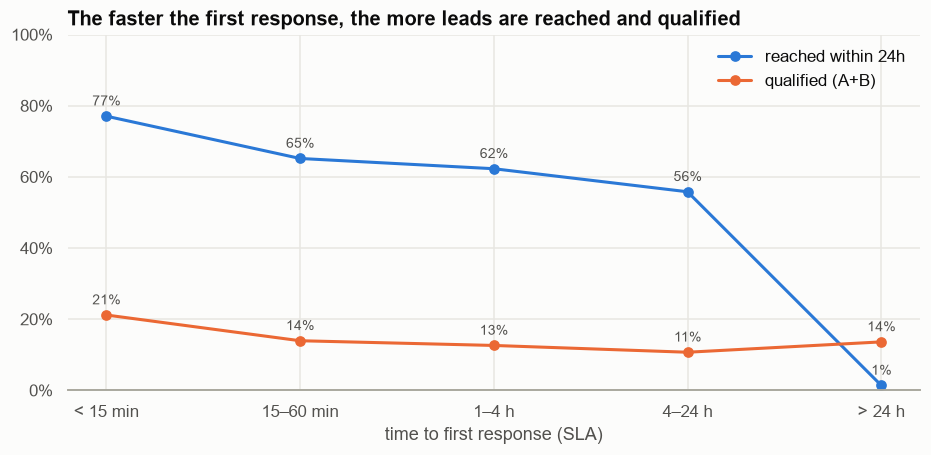

In [7]:
fig, ax = plt.subplots(figsize=(10, 4.2))
x = np.arange(len(evidence))
ax.plot(x, evidence["reached_24h"], marker="o", color=PRIMARY, label="reached within 24h")
ax.plot(x, evidence["share_AB"], marker="o", color=ACCENT, label="qualified (A+B)")
ax.set_xticks(x, evidence.index.astype(str)); pct_axis(ax)
for xi, (r, q) in enumerate(zip(evidence["reached_24h"], evidence["share_AB"])):
    ax.text(xi, r + 0.03, f"{r:.0%}", ha="center", fontsize=9, color=viz.TEXT_2)
    ax.text(xi, q + 0.03, f"{q:.0%}", ha="center", fontsize=9, color=viz.TEXT_2)
ax.set_title("The faster the first response, the more leads are reached and qualified")
ax.set_xlabel("time to first response (SLA)"); ax.legend(frameon=False); ax.set_ylim(0, 1)
save(fig, "03_hypothesis_evidence"); plt.show()

> **Гипотеза (H1).** Если каждому новому лиду в течение 1 минуты автоматически назначать свободного менеджера
> с push-уведомлением и отправлять клиенту сообщение в WhatsApp/SMS («Менеджер позвонит в течение 15 минут»),
> а менеджер обязан позвонить **в течение 15 минут** в рабочее время,
> **то доля лидов, с которыми состоялся разговор в первые 24 часа, вырастет как минимум на 10 п.п.**
> (с ~52% до ≥ 62%), **потому что** клиент ещё «тёплый» и ждёт звонка — в данных лиды с ответом < 15 мин
> дозваниваются в 77% случаев против 52% при более медленном ответе (разрыв 25 п.п.; закладываем
> консервативно 10 п.п.).

- **Метрика продукта, на которую воздействуем:** C1 (через дозвон и квалификацию).
- **Первичная метрика теста:** `reached_24h` — доля лидов с разговором ≥ 30 секунд в первые 24 часа.
  Выбрана потому, что: (а) она измерима за 1 день, а оплата — в среднем через 17+ дней и за 2 недели её не
  набрать; (б) она напрямую связана с C1 (см. дерево метрик).
- **Вторичные метрики:** медианный SLA, доля лидов A+B, доля `Lost` с причиной «не отвечает».
- **Отложенная метрика:** C1 по когортам теста — отслеживаем через 45 дней после окончания.
- **Guardrail-метрики (не должны ухудшиться):** доля лидов `Non target`, число звонков на менеджера в день
  (нагрузка), доля жалоб/отписок от сообщений.
- **H0:** доли `reached_24h` в группах A и B равны.

## 5. Дизайн A/B-теста (≤ 2 недель)

In [8]:
recent = deals[deals["created_time"] >= "2024-03-01"]
leads_per_day = len(recent) / recent["created_time"].dt.normalize().nunique()

slow = deals["sla_bucket"].isin(["15–60 min", "1–4 h", "4–24 h", "> 24 h"])
p_control = deals.loc[slow, "reached_24h"].mean()
p_treatment = p_control + 0.10
alpha, power = 0.05, 0.80
effect = proportion_effectsize(p_treatment, p_control)
n_per_group = int(np.ceil(NormalIndPower().solve_power(effect, alpha=alpha, power=power, ratio=1)))
days_needed = int(np.ceil(2 * n_per_group / leads_per_day))

n_14 = int(leads_per_day * 14 / 2)
mde_h = NormalIndPower().solve_power(nobs1=n_14, alpha=alpha, power=power, ratio=1)
# обратное преобразование Коэна h -> доля
mde_p = np.sin(np.arcsin(np.sqrt(p_control)) + mde_h / 2) ** 2

design = pd.Series({
    "Лидов в день (с марта 2024)": f"{leads_per_day:.0f}",
    "Baseline reached_24h (контроль)": f"{p_control:.1%}",
    "Ожидаемый уровень в тесте": f"{p_treatment:.1%} (+10 п.п.)",
    "Уровень значимости α / мощность": f"{alpha} / {power:.0%}",
    "Нужно лидов на группу": f"{n_per_group:,}",
    "Дней для набора выборки": days_needed,
    "Длительность теста": "14 дней (2 полные недели — учитывает недельную сезонность)",
    "Лидов на группу за 14 дней": f"{n_14:,}",
    "MDE за 14 дней": f"{(mde_p - p_control) * 100:+.1f} п.п. (до {mde_p:.1%})",
}, name="значение")
design.to_frame()

,значение
Лидов в день (с марта 2024),74
Baseline reached_24h (контроль),52.1%
Ожидаемый уровень в тесте,62.1% (+10 п.п.)
Уровень значимости α / мощность,0.05 / 80%
Нужно лидов на группу,384
Дней для набора выборки,11
Длительность теста,14 дней (2 полные недели — учитывает недельную...
Лидов на группу за 14 дней,519
MDE за 14 дней,+8.6 п.п. (до 60.7%)


**Условия проведения теста:**

| Параметр | Решение |
|---|---|
| Единица рандомизации | лид (новая заявка) |
| Разбиение | 50/50 по последней цифре ID сделки (чётная → B, нечётная → A) — детерминированно и проверяемо |
| Группа A (контроль) | текущий процесс распределения лидов |
| Группа B (тест) | автоназначение менеджера + push + авто-сообщение клиенту + правило «звонок ≤ 15 мин» |
| Кто участвует | все новые лиды из всех источников; одни и те же менеджеры работают с обеими группами |
| Длительность | 14 дней, старт в понедельник; тест не останавливаем досрочно (проблема «подглядывания») |
| Проверка корректности | SRM-тест (хи-квадрат) на равенство размеров групп; сравнение структуры источников |
| Статистический тест | двусторонний z-тест для долей, α = 0.05 |
| Решение | внедряем, если `reached_24h` вырос значимо и guardrail-метрики не ухудшились; через 45 дней подтверждаем по C1 |

**Риски:** менеджеры знают о тесте и могут быстрее звонить и контрольной группе (эффект спилловера) →
эффект будет **недооценён**, т.е. результат консервативный. Чтобы снизить риск, правило «≤ 15 мин» и
уведомления видны менеджеру только на лидах группы B.

### 5.1 Как будет считаться результат (демонстрация на смоделированных данных)
Ниже — код анализа, который запускается после теста. Чтобы показать его работу, генерируем данные с
заложенным эффектом +10 п.п. (это **симуляция**, не реальный результат).

In [9]:
rng = np.random.default_rng(42)
sim = pd.DataFrame({"group": np.repeat(["A", "B"], n_14)})
sim["reached_24h"] = np.where(sim["group"] == "A",
                              rng.random(len(sim)) < p_control,
                              rng.random(len(sim)) < p_treatment)


def analyze_ab(df: pd.DataFrame, metric: str = "reached_24h") -> pd.Series:
    g = df.groupby("group")[metric].agg(["sum", "count", "mean"])
    z, p = proportions_ztest(g["sum"].values, g["count"].values)
    diff = g.loc["B", "mean"] - g.loc["A", "mean"]
    se = np.sqrt(sum(g.loc[x, "mean"] * (1 - g.loc[x, "mean"]) / g.loc[x, "count"] for x in "AB"))
    return pd.Series({"A": f"{g.loc['A', 'mean']:.1%}", "B": f"{g.loc['B', 'mean']:.1%}",
                      "uplift, п.п.": f"{diff:+.1%}",
                      "95% ДИ": f"[{diff - 1.96 * se:+.1%}; {diff + 1.96 * se:+.1%}]",
                      "p-value": f"{p:.4f}", "решение": "отвергаем H0" if p < 0.05 else "не отвергаем H0"})


analyze_ab(sim).to_frame("симуляция")

,симуляция
A,52.4%
B,61.7%
"uplift, п.п.",+9.2%
95% ДИ,[+3.3%; +15.2%]
p-value,0.0026
решение,отвергаем H0


## 6. Ожидаемый бизнес-эффект
Если гипотеза подтвердится и рост дозвона на 10 п.п. перейдёт в C1 пропорционально
(C1 у дозвонившихся выше, чем у недозвонившихся), оценим эффект на CM:

In [10]:
c1_reached = deals.loc[deals["reached_24h"], "is_student"].mean()
c1_not = deals.loc[~deals["reached_24h"], "is_student"].mean()
c1_new = (reached + 0.10) * c1_reached + (1 - reached - 0.10) * c1_not
m = m0.copy(); m["C1"] = base["C1"] * c1_new / deals["is_student"].mean()
pd.Series({
    "C1 у дозвонившихся за 24 ч": f"{c1_reached:.1%}",
    "C1 у остальных": f"{c1_not:.1%}",
    "Ожидаемый рост C1": f"{c1_new / deals['is_student'].mean() - 1:+.1%}",
    "Ожидаемый рост CM за год": f"+€{cm(**m) - cm0:,.0f}",
}).to_frame("оценка")

,оценка
C1 у дозвонившихся за 24 ч,6.8%
C1 у остальных,2.3%
Ожидаемый рост C1,+10.8%
Ожидаемый рост CM за год,"+€385,476"


## 7. Итоги продуктовой аналитики
1. Все продукты прибыльны после маркетинга; CAC €175–189 при CLTV €2.7–4.8k (ROMI 14–26×). Узкое место — конверсия (C1 ≈ 4%).
2. Точка роста — **C1**: самый большой запас и понятный механизм улучшения (37% потерь — недозвон).
3. Дерево метрик: CM ← Revenue ← C1 ← дозвон ← SLA первого контакта.
4. Гипотеза: автоназначение лида + контакт ≤ 15 минут увеличат дозвон в первые 24 ч на ≥ 10 п.п.
5. A/B-тест: 14 дней (нужно ~390 лидов на группу, за 2 недели набирается ~520), α = 0.05, мощность 80%, z-тест для долей; итоговая проверка по C1
   через 45 дней.